# Perda de peso em pacientes oncológicos
**Débora de Cássia de Morais**

Introdução à Ciência de Dados · UFPE · 2026

Análise secundária de Viana et al. (2020). Resposta: percentual de perda de peso nos últimos seis meses. Estimação retrospectiva, sem inferência causal ou diagnóstico de desnutrição.


## Importação da base original

In [1]:
# Instalar o pacote que lê o arquivo original
%pip -q install pyreadstat

import pandas as pd
import pyreadstat
from urllib.request import urlretrieve

# Baixar a base disponibilizada pelos autores
url = (
    "https://journals.plos.org/plosone/article/file"
    "?type=supplementary&id=10.1371/journal.pone.0241305.s001"
)

urlretrieve(url, "base_oncologia_original.sav")

# Carregar os dados e o dicionário das variáveis
dados, metadados = pyreadstat.read_sav(
    "base_oncologia_original.sav"
)

print(f"Pacientes: {dados.shape[0]}")
print(f"Variáveis: {dados.shape[1]}")

display(dados.head())

Pacientes: 135
Variáveis: 44


,ID,Sex,Age,stage_life,length_stay,clas_length_stay,death,ethnicity,tumor_location,height,...,smell_sick,full_quickly,vomit,diarrhea,dry_mouth,problems_swallowing,pain,others,weight_loss,clas_weight_loss
0,33.0,2.0,28.0,2.0,3.0,1.0,2.0,2.0,6.0,1.82,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,0.0,1.0
1,34.0,2.0,22.0,2.0,28.0,2.0,2.0,1.0,3.0,1.77,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,0.0,1.0
2,101.0,2.0,31.0,2.0,3.0,1.0,2.0,1.0,3.0,1.79,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,0.0,1.0
3,44.0,2.0,48.0,2.0,4.0,1.0,2.0,1.0,6.0,1.80,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,0.0,1.0
4,117.0,1.0,53.0,2.0,1.0,1.0,2.0,2.0,2.0,1.60,...,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,0.0,1.0


## Dicionário e qualidade dos dados

In [2]:
# 1. Dicionário: significado das colunas e dados ausentes
dicionario = pd.DataFrame({
    "variavel": dados.columns,
    "descricao": [
        metadados.column_names_to_labels.get(coluna)
        for coluna in dados.columns
    ],
    "ausentes": dados.isna().sum().values,
    "valores_distintos": dados.nunique().values
})

display(dicionario)

# 2. Conferir a codificação das categorias
for coluna in ["Sex", "tumor_location", "absence_appetite",
               "nausea", "clas_weight_loss"]:
    print(
        coluna,
        metadados.variable_value_labels.get(coluna, {})
    )

# 3. Resumir nossa variável resposta
print("\nResumo da perda de peso:")
display(dados["weight_loss"].describe())

print("Perdas negativas:", (dados["weight_loss"] < 0).sum())
print("Perdas iguais a zero:", (dados["weight_loss"] == 0).sum())

# 4. Verificar possíveis registros repetidos
print("\nLinhas duplicadas:", dados.duplicated().sum())
print("IDs repetidos:", dados["ID"].duplicated().sum())

,variavel,descricao,ausentes,valores_distintos
0,ID,None,0,135
1,Sex,Sex,0,2
2,Age,Age,0,51
3,stage_life,Stage Life,0,2
4,length_stay,Length of stay,1,34
5,clas_length_stay,Clasification Length of stay,1,2
6,death,Death,0,2
7,ethnicity,Ethnicity,0,2
8,tumor_location,Tumor location,0,4
9,height,Height (m),0,41


Sex {1.0: 'female', 2.0: 'male'}
tumor_location {1.0: 'upper GI tract', 2.0: 'lower GI tract', 3.0: 'attached glands', 6.0: 'others'}
absence_appetite {1.0: 'yes', 2.0: 'no'}
nausea {1.0: 'yes', 2.0: 'no'}
clas_weight_loss {1.0: 'without loss', 2.0: '>0-9,9%', 3.0: '>=10,0%'}

Resumo da perda de peso:


,weight_loss
count,135.000000
mean,4.536630
std,6.544449
min,0.000000
25%,0.000000
50%,2.400000
75%,5.935000
max,45.940000


Perdas negativas: 0
Perdas iguais a zero: 51

Linhas duplicadas: 0
IDs repetidos: 0


## Seleção de preditores e divisão treino/teste

In [3]:
from sklearn.model_selection import train_test_split

# Sintomas candidatos a explicar a perda de peso
sintomas = [
    "absence_appetite", "nausea", "constipation",
    "mouth_sores", "strange_taste", "smell_sick",
    "full_quickly", "vomit", "diarrhea",
    "dry_mouth", "problems_swallowing", "pain"
]

preditores = ["Age", "Sex", "tumor_location"] + sintomas

# Criar uma cópia para a análise, preservando a base original
base = dados[preditores + ["weight_loss"]].copy()

# Conferir preenchimento das variáveis escolhidas
print("Dados ausentes nas variáveis selecionadas:")
print(base.isna().sum())

# Examinar os cinco maiores valores da resposta
print("\nCinco maiores perdas registradas:")
display(
    base.nlargest(5, "weight_loss")[
        ["Age", "Sex", "tumor_location", "weight_loss"]
    ]
)

# X = informações de entrada; y = resposta a estimar
X = base[preditores]
y = base["weight_loss"]

# Reservar 20% dos pacientes para teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print(f"\nTreino: {len(X_treino)} pacientes")
print(f"Teste: {len(X_teste)} pacientes")

Dados ausentes nas variáveis selecionadas:
Age                    0
Sex                    0
tumor_location         0
absence_appetite       0
nausea                 0
constipation           0
mouth_sores            0
strange_taste          0
smell_sick             0
full_quickly           0
vomit                  0
diarrhea               0
dry_mouth              0
problems_swallowing    0
pain                   0
weight_loss            0
dtype: int64

Cinco maiores perdas registradas:


,Age,Sex,tumor_location,weight_loss
128,74.0,2.0,1.0,45.94
118,52.0,1.0,2.0,23.59
125,64.0,2.0,3.0,22.46
96,67.0,1.0,3.0,21.20
115,62.0,2.0,1.0,21.16



Treino: 108 pacientes
Teste: 27 pacientes


## Análise exploratória do treino

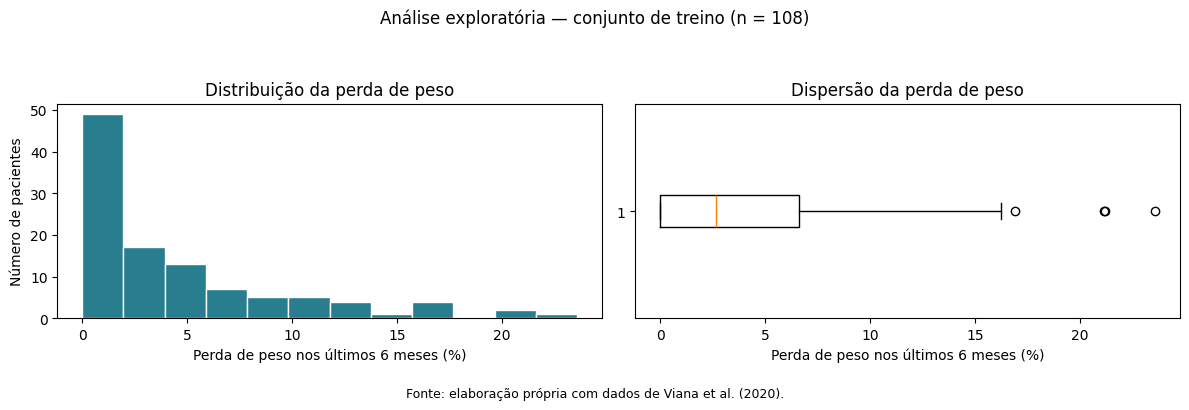

Resumo da perda de peso no treino:


,weight_loss
count,108.00
mean,4.35
std,5.38
min,0.00
25%,0.00
50%,2.68
75%,6.60
max,23.59


In [4]:
import matplotlib.pyplot as plt

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

# Histograma
eixos[0].hist(
    y_treino,
    bins=12,
    color="#287D8E",
    edgecolor="white"
)
eixos[0].set_title("Distribuição da perda de peso")
eixos[0].set_xlabel("Perda de peso nos últimos 6 meses (%)")
eixos[0].set_ylabel("Número de pacientes")

# Boxplot
eixos[1].boxplot(y_treino, vert=False)
eixos[1].set_title("Dispersão da perda de peso")
eixos[1].set_xlabel("Perda de peso nos últimos 6 meses (%)")

fig.suptitle("Análise exploratória — conjunto de treino (n = 108)")
fig.text(
    0.5, 0.01,
    "Fonte: elaboração própria com dados de Viana et al. (2020).",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.06, 1, 0.92])
plt.show()

print("Resumo da perda de peso no treino:")
display(y_treino.describe().round(2))

## Codificação de categorias

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Idade é quantitativa; as outras entradas são categóricas
categoricas = ["Sex", "tumor_location"] + sintomas

# Uma categoria de cada variável será a referência.
# As demais serão representadas por colunas de 0 e 1.
preparador = ColumnTransformer(
    transformers=[
        ("idade", "passthrough", ["Age"]),
        (
            "categorias",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
                sparse_output=False
            ),
            categoricas
        )
    ]
)

# Aprender as categorias usando apenas o treino
treino_preparado = preparador.fit_transform(X_treino)

# Visualizar o resultado com os nomes das novas colunas
treino_visualizacao = pd.DataFrame(
    treino_preparado,
    columns=preparador.get_feature_names_out(),
    index=X_treino.index
)

display(treino_visualizacao.head())

print("Número de preditores após a transformação:",
      treino_visualizacao.shape[1])

print("\nCategorias de referência:")
codificador = preparador.named_transformers_["categorias"]

for coluna, categorias in zip(
    categoricas, codificador.categories_
):
    referencia = categorias[0]
    significado = metadados.variable_value_labels.get(
        coluna, {}
    ).get(referencia, referencia)

    print(f"{coluna}: {referencia} = {significado}")

,idade__Age,categorias__Sex_2.0,categorias__tumor_location_2.0,categorias__tumor_location_3.0,categorias__tumor_location_6.0,categorias__absence_appetite_2.0,categorias__nausea_2.0,categorias__constipation_2.0,categorias__mouth_sores_2.0,categorias__strange_taste_2.0,categorias__smell_sick_2.0,categorias__full_quickly_2.0,categorias__vomit_2.0,categorias__diarrhea_2.0,categorias__dry_mouth_2.0,categorias__problems_swallowing_2.0,categorias__pain_2.0
11,67.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
123,74.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
80,69.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0
104,76.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
83,54.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


Número de preditores após a transformação: 17

Categorias de referência:
Sex: 1.0 = female
tumor_location: 1.0 = upper GI tract
absence_appetite: 1.0 = yes
nausea: 1.0 = yes
constipation: 1.0 = yes
mouth_sores: 1.0 = yes
strange_taste: 1.0 = yes
smell_sick: 1.0 = yes
full_quickly: 1.0 = yes
vomit: 1.0 = yes
diarrhea: 1.0 = yes
dry_mouth: 1.0 = yes
problems_swallowing: 1.0 = yes
pain: 1.0 = yes


## Validação cruzada e escolha dos ajustes

In [6]:
import numpy as np

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import (
    KFold, GridSearchCV, cross_val_score
)

# Mesmas divisões para comparar todos os modelos
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# LASSO: codificar categorias, padronizar e ajustar
pipeline_lasso = Pipeline([
    ("preparacao", clone(preparador)),
    ("padronizacao", StandardScaler()),
    ("modelo", Lasso(max_iter=20000))
])

busca_lasso = GridSearchCV(
    estimator=pipeline_lasso,
    param_grid={
        "modelo__alpha": np.logspace(-3, 1.5, 30)
    },
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    error_score="raise"
)

# FLORESTA: codificar categorias e ajustar
pipeline_floresta = Pipeline([
    ("preparacao", clone(preparador)),
    ("modelo", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=1
    ))
])

busca_floresta = GridSearchCV(
    estimator=pipeline_floresta,
    param_grid={
        "modelo__max_depth": [2, 4, None],
        "modelo__min_samples_leaf": [3, 8],
        "modelo__max_features": [0.7, 1.0]
    },
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    error_score="raise"
)

print("Ajustando Lasso...")
busca_lasso.fit(X_treino, y_treino)

print("Ajustando floresta aleatória...")
busca_floresta.fit(X_treino, y_treino)

# Referência: prever sempre a mediana de cada parte de treino
erros_referencia = -cross_val_score(
    DummyRegressor(strategy="median"),
    X_treino,
    y_treino,
    scoring="neg_mean_absolute_error",
    cv=cv
)

# Guardar os modelos ajustados
modelos = {
    "Lasso": busca_lasso.best_estimator_,
    "Floresta aleatória": busca_floresta.best_estimator_
}

# Resultados da validação interna
resultados_cv = pd.DataFrame({
    "Modelo": [
        "Referência — mediana",
        "Lasso",
        "Floresta aleatória"
    ],
    "MAE médio (p.p.)": [
        erros_referencia.mean(),
        -busca_lasso.best_score_,
        -busca_floresta.best_score_
    ]
}).sort_values("MAE médio (p.p.)")

display(resultados_cv.round(3))

print("\nParâmetros escolhidos para o Lasso:")
print(busca_lasso.best_params_)

print("\nParâmetros escolhidos para a floresta:")
print(busca_floresta.best_params_)

Ajustando Lasso...
Ajustando floresta aleatória...


,Modelo,MAE médio (p.p.)
2,Floresta aleatória,3.838
0,Referência — mediana,3.849
1,Lasso,3.979



Parâmetros escolhidos para o Lasso:
{'modelo__alpha': np.float64(0.4344412298729369)}

Parâmetros escolhidos para a floresta:
{'modelo__max_depth': None, 'modelo__max_features': 0.7, 'modelo__min_samples_leaf': 3}


## Avaliação final no teste

In [7]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Ajustar a referência usando somente os pacientes de treino
referencia = DummyRegressor(strategy="median")
referencia.fit(X_treino, y_treino)

modelos_avaliacao = {
    "Referência — mediana": referencia,
    **modelos
}

previsoes_teste = {}
linhas_resultados = []

for nome, modelo in modelos_avaliacao.items():
    previsto = modelo.predict(X_teste)
    previsoes_teste[nome] = previsto

    linhas_resultados.append({
        "Modelo": nome,
        "MAE teste (p.p.)": mean_absolute_error(
            y_teste, previsto
        ),
        "RMSE teste (p.p.)": np.sqrt(
            mean_squared_error(y_teste, previsto)
        ),
        "R² teste": r2_score(y_teste, previsto)
    })

resultados_teste = pd.DataFrame(
    linhas_resultados
).sort_values("MAE teste (p.p.)")

display(resultados_teste.round(3))

print("Número de pacientes no teste:", len(y_teste))

,Modelo,MAE teste (p.p.),RMSE teste (p.p.),R² teste
0,Referência — mediana,5.375,10.200,-0.069
2,Floresta aleatória,5.429,9.356,0.100
1,Lasso,5.619,9.810,0.011


Número de pacientes no teste: 27


## Diagnóstico dos erros

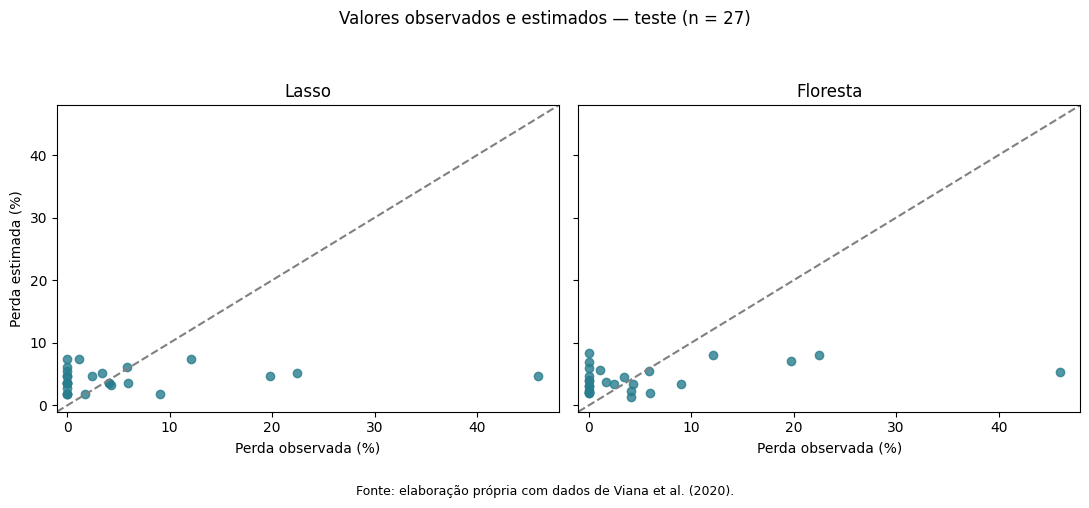

Cinco maiores perdas observadas no teste:


,Observado,Referência,Lasso,Floresta,Erro absoluto — Lasso,Erro absoluto — Floresta
128,45.94,2.68,4.68,5.42,41.26,40.52
125,22.46,2.68,5.11,8.03,17.35,14.43
119,19.76,2.68,4.68,7.09,15.08,12.67
110,12.10,2.68,7.45,8.10,4.65,4.00
44,9.03,2.68,1.78,3.38,7.25,5.65


In [8]:
# Comparar valores reais e estimados no teste
comparacao = pd.DataFrame({
    "Observado": y_teste,
    "Referência": previsoes_teste["Referência — mediana"],
    "Lasso": previsoes_teste["Lasso"],
    "Floresta": previsoes_teste["Floresta aleatória"]
})

fig, eixos = plt.subplots(
    1, 2, figsize=(11, 5), sharex=True, sharey=True
)

limite_inferior = min(0, comparacao.min().min()) - 1
limite_superior = comparacao.max().max() + 2

for eixo, nome in zip(eixos, ["Lasso", "Floresta"]):
    eixo.scatter(
        comparacao["Observado"],
        comparacao[nome],
        color="#287D8E",
        alpha=0.8
    )

    # Na linha tracejada, estimativa e valor real seriam iguais
    eixo.plot(
        [limite_inferior, limite_superior],
        [limite_inferior, limite_superior],
        "--", color="gray"
    )

    eixo.set_title(nome)
    eixo.set_xlabel("Perda observada (%)")
    eixo.set_xlim(limite_inferior, limite_superior)
    eixo.set_ylim(limite_inferior, limite_superior)

eixos[0].set_ylabel("Perda estimada (%)")

fig.suptitle("Valores observados e estimados — teste (n = 27)")
fig.text(
    0.5, 0.01,
    "Fonte: elaboração própria com dados de Viana et al. (2020).",
    ha="center", fontsize=9
)

plt.tight_layout(rect=[0, 0.06, 1, 0.93])
plt.savefig("observado_estimado.png", dpi=300, bbox_inches="tight")
plt.show()

# Erros absolutos: tamanho do erro, sem considerar o sinal
comparacao["Erro absoluto — Lasso"] = (
    comparacao["Observado"] - comparacao["Lasso"]
).abs()

comparacao["Erro absoluto — Floresta"] = (
    comparacao["Observado"] - comparacao["Floresta"]
).abs()

print("Cinco maiores perdas observadas no teste:")
display(
    comparacao.sort_values(
        "Observado", ascending=False
    ).head().round(2)
)